# Notebook 2: Error analysis, uncertainty, 2025 watch list and website data

Run this **after** `export_collapse_full.ipynb`. It reads two files that notebook saved in your Drive:
`my_table.csv` (131,550 rows with the 24 inputs) and `my_live_2024.csv` (the 2024 flows, whose answer is not known yet).

What it does:
1. rebuilds the honest out-of-sample predictions (walk-forward 2011-2020 and frozen 2021-2024),
2. measures how sure we can be that the model beats the volatility rule (bootstrap over countries),
3. tests which groups of inputs actually help (ablation),
4. **error analysis**: where the model fails and why,
5. trains the final model and makes the **2025 watch list** with the top reasons for every warning,
6. writes small JSON files for the website into a `website_data` folder in your Drive.

Run it top to bottom (Runtime -> Run all). It takes about 5-10 minutes.

## Step 0: Setup and load

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE = "/content/drive/MyDrive"

Mounted at /content/drive


In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

table = pd.read_csv(f"{DRIVE}/my_table.csv", dtype={"hs2": str})
live = pd.read_csv(f"{DRIVE}/my_live_2024.csv", dtype={"hs2": str})
print("table rows:", len(table), "| 2024 rows:", len(live))

OUT = f"{DRIVE}/website_data"
os.makedirs(OUT, exist_ok=True)

table rows: 131550 | 2024 rows: 6487


## Step 1: Names for countries and product groups

Only used to make the results readable. Country names come from the World Bank file; product names are typed in by hand.

In [3]:
PRODUCT_NAMES = {
 "01":"Live animals","02":"Meat","03":"Fish and seafood","04":"Dairy, eggs, honey","05":"Other animal products",
 "06":"Plants and flowers","07":"Vegetables","08":"Fruit and nuts","09":"Coffee, tea, spices","10":"Cereals (rice, wheat)",
 "11":"Milling products","12":"Oil seeds","13":"Lacs, gums","14":"Other plant products","15":"Animal and vegetable oils",
 "16":"Meat and fish preparations","17":"Sugar","18":"Cocoa","19":"Cereal preparations","20":"Fruit and vegetable preparations",
 "21":"Misc. food preparations","22":"Beverages","23":"Food waste, animal feed","24":"Tobacco","25":"Salt, stone, cement",
 "26":"Ores","27":"Mineral fuels, oil","28":"Inorganic chemicals","29":"Organic chemicals","30":"Pharmaceuticals (medicines)",
 "31":"Fertilisers","32":"Dyes, paints, inks","33":"Essential oils, cosmetics","34":"Soap, detergents","35":"Glues, enzymes",
 "36":"Explosives","37":"Photographic goods","38":"Misc. chemical products","39":"Plastics","40":"Rubber",
 "41":"Raw hides and leather","42":"Leather goods, bags","43":"Furs","44":"Wood","45":"Cork","46":"Basketwork",
 "47":"Wood pulp","48":"Paper","49":"Books, printed matter","50":"Silk","51":"Wool","52":"Cotton","53":"Other plant fibres",
 "54":"Man-made filaments","55":"Man-made staple fibres","56":"Wadding, ropes","57":"Carpets","58":"Special fabrics",
 "59":"Coated fabrics","60":"Knitted fabrics","61":"Knitted clothing","62":"Woven clothing","63":"Other textile articles",
 "64":"Footwear","65":"Headgear","66":"Umbrellas","67":"Feathers, artificial flowers","68":"Stone articles","69":"Ceramics",
 "70":"Glass","71":"Gems, jewellery, gold","72":"Iron and steel","73":"Iron and steel articles","74":"Copper","75":"Nickel",
 "76":"Aluminium","78":"Lead","79":"Zinc","80":"Tin","81":"Other base metals","82":"Tools, cutlery","83":"Misc. metal articles",
 "84":"Machinery, computers","85":"Electrical machinery, electronics","86":"Railway equipment","87":"Vehicles, auto parts",
 "88":"Aircraft","89":"Ships and boats","90":"Optical, medical instruments","91":"Clocks and watches","92":"Musical instruments",
 "93":"Arms and ammunition","94":"Furniture, lighting","95":"Toys, sports goods","96":"Misc. manufactured articles",
 "97":"Art and antiques"}
LUMPY = ["27", "71", "88", "89", "93"]     # fuel, gems/gold, aircraft, ships, arms: few huge one-off deals

gdp_names = pd.read_csv("https://raw.githubusercontent.com/datasets/gdp/main/data/gdp.csv")
COUNTRY_NAMES = {}
for code_, name in zip(gdp_names["Country Code"], gdp_names["Country Name"]):
    COUNTRY_NAMES[code_] = name
COUNTRY_NAMES.update({"TWN": "Taiwan", "ANT": "Netherlands Antilles", "SCG": "Serbia and Montenegro",
                      "SUN": "Soviet Union", "CSK": "Czechoslovakia", "YUG": "Yugoslavia", "S19": "Other Asia (Taiwan)",
                      "COK": "Cook Islands", "SHN": "Saint Helena", "SPM": "Saint Pierre and Miquelon",
                      "WLF": "Wallis and Futuna", "NIU": "Niue", "TKL": "Tokelau", "MSR": "Montserrat",
                      "AIA": "Anguilla", "BES": "Bonaire", "IOT": "British Indian Ocean Terr.", "CXR": "Christmas Island",
                      "CCK": "Cocos Islands", "NFK": "Norfolk Island", "PCN": "Pitcairn", "ESH": "Western Sahara",
                      "ATF": "French Southern Terr.", "FLK": "Falkland Islands", "BLM": "Saint Barthelemy",
                      "MNP": "Northern Mariana Islands", "GUM": "Guam", "ASM": "American Samoa", "VGB": "British Virgin Islands",
                      "GIB": "Gibraltar", "PRK": "North Korea"})

def country_name(iso):
    return COUNTRY_NAMES.get(iso, iso)
def product_name(hs2):
    return PRODUCT_NAMES.get(hs2, "HS " + hs2)
print(country_name("NGA"), "|", product_name("30"))

Nigeria | Pharmaceuticals (medicines)


## Step 2: Add the 3 co-movement inputs to the 2024 rows

Same recipe as Step 9 of the first notebook, so the 2024 rows have all 24 inputs.

In [4]:
live["fell"] = (live["chg_0"] < -0.3).astype(int)
g = live.groupby("iso3_d")
live["buyer_other_fell_share"] = (g.fell.transform("sum") - live.fell) / (g.fell.transform("size") - 1)
live["buyer_other_chg_mean"] = (g.chg_0.transform("sum") - live.chg_0) / (g.chg_0.transform("count") - 1)
g = live.groupby("hs2")
live["product_other_fell_share"] = (g.fell.transform("sum") - live.fell) / (g.fell.transform("size") - 1)
NEW = ["buyer_other_fell_share", "buyer_other_chg_mean", "product_other_fell_share"]
live[NEW] = live[NEW].replace([np.inf, -np.inf], np.nan)

HISTORY = ["log_trade", "chg_0", "chg_1", "chg_2", "volatility", "trend_3y", "years_traded_5"]
MARKET  = ["buyer_imp_growth", "buyer_all_imp_growth", "india_share", "india_share_chg", "india_prod_growth", "partner_share"]
COUNTRY = ["gdp_growth_d", "gdp_share_d", "pop_share_d", "log_dist", "contig", "comlang_off", "wto_d", "fta_wto"]
ALL_INPUTS = HISTORY + MARKET + COUNTRY + NEW
print(len(ALL_INPUTS), "inputs")

24 inputs


## Step 3: Out-of-sample predictions for every past row

Same honest design as before. For answer year Y the model is trained only on rows whose answer was known before Y.
- **Walk-forward** (answer years 2011-2020): retrain every year.
- **Frozen** (answer years 2021-2024): train once on answers up to 2020, never retrain.

Every row from 2009 onwards now gets a risk score from a model that never saw its answer.
The **watch list** for a year = the 10% of flows with the highest risk that year.

In [5]:
def trees():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)

pred_parts = []
for Y in range(2011, 2025):
    if Y <= 2020:
        train = table[table.year <= Y - 2]
    else:
        train = table[table.year <= 2019]
    test = table[table.year == Y - 1].copy()
    m = trees().fit(train[ALL_INPUTS], train["collapse"])
    test["risk"] = m.predict_proba(test[ALL_INPUTS])[:, 1]
    test["rule"] = test["volatility"].fillna(train["volatility"].median())
    test["answer_year"] = Y
    test["design"] = "walk-forward" if Y <= 2020 else "frozen"
    k = int(len(test) * 0.10)
    test["on_list"] = 0
    test.loc[test["risk"].nlargest(k).index, "on_list"] = 1
    test["on_rule_list"] = 0
    test.loc[test["rule"].nlargest(k).index, "on_rule_list"] = 1
    # second baseline: rank by this year's change (biggest jump first)
    test["jump"] = test["chg_0"]
    test["on_jump_list"] = 0
    test.loc[test["jump"].nlargest(k).index, "on_jump_list"] = 1
    pred_parts.append(test)
    print("done", Y)
pred = pd.concat(pred_parts)
print(len(pred), "out-of-sample predictions")

done 2011
done 2012
done 2013
done 2014
done 2015
done 2016
done 2017
done 2018
done 2019
done 2020
done 2021
done 2022
done 2023
done 2024
82450 out-of-sample predictions


## Step 4: Scores per year, and how sure we are (bootstrap)

Besides the volatility rule we also score a second simple rule, the **jump rule**: rank flows by this year's change
(the biggest rise first), because many of the highest-risk flows are ones that just jumped.

The AUC difference between the model and the volatility rule could be luck. To check, we **resample whole countries**
(flows to the same country move together, so countries are the honest unit) 500 times and recompute the difference.
If the 95% range stays above 0, the model is clearly better.

In [6]:
by_year = []
for Y, t in pred.groupby("answer_year"):
    by_year.append({"answer_year": int(Y), "design": t.design.iloc[0], "rows": len(t), "base_rate": t.collapse.mean(),
                    "auc_model": roc_auc_score(t.collapse, t.risk), "auc_rule": roc_auc_score(t.collapse, t.rule),
                    "top10_model": t[t.on_list == 1].collapse.mean(), "top10_rule": t[t.on_rule_list == 1].collapse.mean(),
                    "pr_model": average_precision_score(t.collapse, t.risk), "pr_rule": average_precision_score(t.collapse, t.rule),
                    "auc_jump": roc_auc_score(t.collapse, t.jump), "top10_jump": t[t.on_jump_list == 1].collapse.mean(),
                    "pr_jump": average_precision_score(t.collapse, t.jump),
                    "recall_model": t[t.collapse == 1].on_list.mean(), "recall_rule": t[t.collapse == 1].on_rule_list.mean()})
by_year = pd.DataFrame(by_year)
print(by_year.round(3).to_string(index=False))

def auc_by_year_mean(t, col):
    # average of the per-year AUCs (same as the main results)
    vals = []
    for Y, ty in t.groupby("answer_year"):
        if ty.collapse.nunique() == 2:
            vals.append(roc_auc_score(ty.collapse, ty[col]))
    return np.mean(vals)

rng = np.random.default_rng(0)
boot = {}
for design in ["walk-forward", "frozen"]:
    t = pred[pred.design == design]
    countries = t.iso3_d.unique()
    rows_of = {c: idx for c, idx in t.groupby("iso3_d").indices.items()}
    diffs = []
    for b in range(500):
        pick = rng.choice(countries, size=len(countries), replace=True)
        idx = np.concatenate([rows_of[c] for c in pick])
        tb = t.iloc[idx]
        diffs.append(auc_by_year_mean(tb, "risk") - auc_by_year_mean(tb, "rule"))
    point = auc_by_year_mean(t, "risk") - auc_by_year_mean(t, "rule")
    boot[design] = {"auc_gain": point, "low": float(np.percentile(diffs, 2.5)), "high": float(np.percentile(diffs, 97.5))}
    print(f"{design}: model AUC minus rule AUC = {point:.3f}  (95% range {boot[design]['low']:.3f} to {boot[design]['high']:.3f})")

 answer_year       design  rows  base_rate  auc_model  auc_rule  top10_model  top10_rule  pr_model  pr_rule  auc_jump  top10_jump  pr_jump  recall_model  recall_rule
        2011 walk-forward  5129      0.159      0.763     0.729        0.508       0.402     0.409    0.333     0.681       0.498    0.390         0.318        0.252
        2012 walk-forward  5476      0.250      0.715     0.681        0.587       0.519     0.469    0.422     0.619       0.589    0.423         0.234        0.207
        2013 walk-forward  5652      0.219      0.716     0.682        0.524       0.473     0.421    0.381     0.621       0.506    0.374         0.239        0.216
        2014 walk-forward  5746      0.224      0.751     0.694        0.545       0.474     0.460    0.388     0.625       0.519    0.398         0.244        0.212
        2015 walk-forward  5843      0.284      0.716     0.683        0.608       0.526     0.501    0.440     0.607       0.596    0.441         0.214        0.185
    

## Step 5: Which groups of inputs help? (ablation)

Walk-forward 2011-2020 with the boosted trees, adding one group of inputs at a time.

In [7]:
groups = [("history only", HISTORY),
          ("+ market (buyer and product)", HISTORY + MARKET),
          ("+ country (GDP, gravity)", HISTORY + MARKET + COUNTRY),
          ("+ co-movement (all 24)", ALL_INPUTS)]
ablation = []
for label, cols in groups:
    aucs = []
    for Y in range(2011, 2021):
        train = table[table.year <= Y - 2]
        test = table[table.year == Y - 1]
        m = trees().fit(train[cols], train["collapse"])
        aucs.append(roc_auc_score(test["collapse"], m.predict_proba(test[cols])[:, 1]))
    ablation.append({"inputs": label, "n_inputs": len(cols), "auc": float(np.mean(aucs))})
    print(f"{label:32s} {len(cols):2d} inputs  AUC {np.mean(aucs):.3f}")

history only                      7 inputs  AUC 0.722
+ market (buyer and product)     13 inputs  AUC 0.726
+ country (GDP, gravity)         21 inputs  AUC 0.726
+ co-movement (all 24)           24 inputs  AUC 0.730


## Step 6: Error analysis

Two kinds of mistakes, using the top-10% watch list:
- **false alarm**: on the watch list, did not collapse
- **missed collapse**: collapsed, but not on the watch list

We look at them by product type, by flow size and by how steady the flow was.

In [8]:
pred["lumpy"] = pred.hs2.isin(LUMPY)
pred["kind"] = "correct calm"
pred.loc[(pred.on_list == 1) & (pred.collapse == 1), "kind"] = "caught"
pred.loc[(pred.on_list == 1) & (pred.collapse == 0), "kind"] = "false alarm"
pred.loc[(pred.on_list == 0) & (pred.collapse == 1), "kind"] = "missed"

# 6a. lumpy products vs the rest
lumpy_rows = []
for label, t in [("lumpy (fuel, gems, aircraft, ships, arms)", pred[pred.lumpy]), ("all other products", pred[~pred.lumpy])]:
    lumpy_rows.append({"group": label, "share_of_rows": len(t) / len(pred),
                       "share_of_watch_list": t.on_list.sum() / pred.on_list.sum(),
                       "collapse_rate": t.collapse.mean(), "watch_list_hit_rate": t[t.on_list == 1].collapse.mean(),
                       "auc_model": roc_auc_score(t.collapse, t.risk), "auc_rule": roc_auc_score(t.collapse, t.rule)})
lumpy_df = pd.DataFrame(lumpy_rows)
print(lumpy_df.round(3).to_string(index=False))

                                    group  share_of_rows  share_of_watch_list  collapse_rate  watch_list_hit_rate  auc_model  auc_rule
lumpy (fuel, gems, aircraft, ships, arms)           0.04                0.116          0.361                0.593      0.721     0.672
                       all other products           0.96                0.884          0.216                0.529      0.717     0.685


In [9]:
# 6b. by how steady the flow was (volatility in thirds) and by size
pred["steadiness"] = pd.qcut(pred.volatility.rank(method="first"), 3, labels=["steady", "medium", "jumpy"]).astype(str)
pred.loc[pred.volatility.isna(), "steadiness"] = "new flow"
pred["size"] = pd.cut(pred.v, [0, 10_000, 100_000, 1e12], labels=["$1-10M", "$10-100M", "over $100M"]).astype(str)

band_rows = []
for col in ["steadiness", "size"]:
    for val, t in pred.groupby(col):
        if t.collapse.nunique() < 2: continue
        band_rows.append({"by": col, "band": val, "rows": len(t), "collapse_rate": t.collapse.mean(),
                          "share_caught": t[t.collapse == 1].on_list.mean(),
                          "auc_model": roc_auc_score(t.collapse, t.risk), "auc_rule": roc_auc_score(t.collapse, t.rule)})
bands = pd.DataFrame(band_rows)
print(bands.round(3).to_string(index=False))

        by       band  rows  collapse_rate  share_caught  auc_model  auc_rule
steadiness      jumpy 27378          0.359         0.406      0.671     0.598
steadiness     medium 27378          0.197         0.047      0.631     0.558
steadiness   new flow   316          0.630         0.779      0.604     0.431
steadiness     steady 27378          0.104         0.003      0.620     0.563
      size     $1-10M 47469          0.247         0.244      0.696     0.656
      size   $10-100M 27298          0.191         0.232      0.736     0.710
      size over $100M  7683          0.177         0.255      0.753     0.752


In [10]:
# 6c. Why are collapses missed? Compare missed vs caught collapses.
# 'buyer_next_imp_growth' is the buyer's total import change in the ANSWER year: the model could not know it.
# It is used here only to explain the mistakes, never as an input.
nxt = table[["iso3_d", "year", "buyer_all_imp_growth"]].drop_duplicates(["iso3_d", "year"]).copy()
nxt["year"] = nxt["year"] - 1
nxt = nxt.rename(columns={"buyer_all_imp_growth": "buyer_next_imp_growth"})
pred = pred.merge(nxt, on=["iso3_d", "year"], how="left")

cmp_cols = ["volatility", "chg_0", "years_traded_5", "log_trade", "buyer_all_imp_growth", "buyer_next_imp_growth", "next_chg"]
miss_vs_caught = pred[pred.kind.isin(["missed", "caught"])].groupby("kind")[cmp_cols].median()
print(miss_vs_caught.round(3).to_string())

missed = pred[pred.kind == "missed"]
caught = pred[pred.kind == "caught"]
facts = {
    "missed_total": int(len(missed)), "caught_total": int(len(caught)),
    "missed_share_steady": float((missed.steadiness == "steady").mean()),
    "caught_share_steady": float((caught.steadiness == "steady").mean()),
    "missed_share_full_stop": float((missed.next_chg.isna()).mean()),
    "missed_median_drop": float(np.exp(missed.next_chg.median()) - 1),
    "caught_median_drop": float(np.exp(caught.next_chg.median()) - 1),
    "missed_share_buyer_shock": float((missed.buyer_next_imp_growth < -0.1).mean()),
    "all_share_buyer_shock": float((pred.buyer_next_imp_growth < -0.1).mean()),
    "caught_also_on_rule_list": float(caught.on_rule_list.mean()),
    "caught_not_already_falling": float((caught.chg_0 > -0.3).mean()),
    "all_collapses": int(pred.collapse.sum()),
    "share_of_collapses_caught": float(len(caught) / pred.collapse.sum()),
    "share_of_collapses_caught_rule": float(pred[pred.collapse == 1].on_rule_list.mean()),
}
for k_, v_ in facts.items(): print(k_, round(v_, 3))

        volatility  chg_0  years_traded_5  log_trade  buyer_all_imp_growth  buyer_next_imp_growth  next_chg
kind                                                                                                       
caught       1.356  1.312             5.0      8.524                 0.050                  0.020    -1.172
missed       0.491  0.120             5.0      8.594                 0.039                 -0.028    -0.557
missed_total 13878
caught_total 4417
missed_share_steady 0.205
caught_share_steady 0.002
missed_share_full_stop 0.005
missed_median_drop -0.427
caught_median_drop -0.69
missed_share_buyer_shock 0.261
all_share_buyer_shock 0.151
caught_also_on_rule_list 0.559
caught_not_already_falling 0.927
all_collapses 18295
share_of_collapses_caught 0.241
share_of_collapses_caught_rule 0.209


In [11]:
# 6d. A few real examples of each kind (from the frozen 2021-2024 test), largest flows first
def example_rows(kind, n=5):
    t = pred[(pred.kind == kind) & (pred.design == "frozen")].sort_values("v", ascending=False).head(n)
    out = []
    for _, r in t.iterrows():
        out.append({"country": country_name(r.iso3_d), "product": product_name(r.hs2), "year": int(r.year),
                    "value_musd": round(r.v / 1000, 1), "risk": round(r.risk, 3),
                    "change_next_year": None if pd.isna(r.next_chg) else round(float(np.exp(r.next_chg) - 1), 3)})
    return out
examples = {k_: example_rows(k_) for k_ in ["caught", "missed", "false alarm"]}
for k_, rows in examples.items():
    print(k_); print(pd.DataFrame(rows).to_string(index=False))

caught
     country               product  year  value_musd  risk  change_next_year
       China        Iron and steel  2020      2564.2 0.553            -0.410
   Indonesia    Mineral fuels, oil  2022      2365.5 0.443            -0.551
  Bangladesh Cereals (rice, wheat)  2021      2323.1 0.541            -0.324
Saudi Arabia    Mineral fuels, oil  2021      2293.4 0.595            -0.311
       China             Aluminium  2021      2058.4 0.503            -0.812
missed
             country                           product  year  value_musd  risk  change_next_year
United Arab Emirates             Gems, jewellery, gold  2023     10469.0 0.212            -0.303
Hong Kong SAR, China             Gems, jewellery, gold  2023      6752.4 0.246            -0.274
       United States                Mineral fuels, oil  2023      5249.3 0.262            -0.366
United Arab Emirates Electrical machinery, electronics  2023      5248.9 0.219            -0.332
               China                   

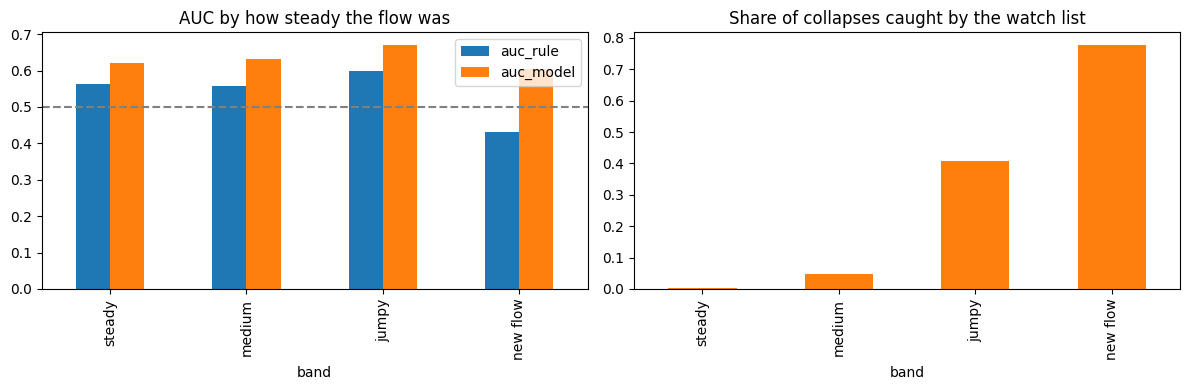

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = bands[bands.by == "steadiness"].set_index("band").loc[["steady", "medium", "jumpy", "new flow"]]
s[["auc_rule", "auc_model"]].plot(kind="bar", ax=axes[0], title="AUC by how steady the flow was")
axes[0].axhline(0.5, color="grey", ls="--")
s["share_caught"].plot(kind="bar", ax=axes[1], color="tab:orange", title="Share of collapses caught by the watch list")
plt.tight_layout(); plt.show()

## Step 7: The final model and the 2025 watch list

Train on **every** row with a known answer (answers up to 2024), then score the 2024 flows: their answer is 2025, not known yet.
We use **XGBoost** here. It scored the same as the boosted trees (AUC 0.735 vs 0.731 walk-forward) and it can split each
risk score into the contribution of every input (**SHAP values**), which gives the reasons shown on the website.

In [13]:
final = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                      random_state=0, n_jobs=-1)
final.fit(table[ALL_INPUTS].astype(float), table["collapse"])
live["risk"] = final.predict_proba(live[ALL_INPUTS].astype(float))[:, 1]

# SHAP: one contribution per input per row (last column is the starting value)
import xgboost as xgb
contrib = final.get_booster().predict(xgb.DMatrix(live[ALL_INPUTS].astype(float)), pred_contribs=True)[:, :-1]

PLAIN = {"log_trade": "size of the flow", "chg_0": "change this year", "chg_1": "change last year", "chg_2": "change 2 years ago",
         "volatility": "how jumpy it has been", "trend_3y": "3-year trend", "years_traded_5": "years traded (of last 5)",
         "buyer_imp_growth": "buyer's imports of this product", "buyer_all_imp_growth": "buyer's total imports",
         "india_share": "India's share of buyer's market", "india_share_chg": "change in India's share",
         "india_prod_growth": "India's exports of this product (all buyers)", "partner_share": "buyer's weight in India's exports",
         "gdp_growth_d": "buyer's GDP growth", "gdp_share_d": "buyer's economy size", "pop_share_d": "buyer's population",
         "log_dist": "distance", "contig": "shares a border", "comlang_off": "shared language", "wto_d": "buyer in WTO",
         "fta_wto": "trade agreement", "buyer_other_fell_share": "India's other products to this buyer falling",
         "buyer_other_chg_mean": "India's other products to this buyer (avg change)",
         "product_other_fell_share": "this product falling in other countries"}

k = int(len(live) * 0.10)
cut = live["risk"].nlargest(k).min()
watch = []
for i, (_, r) in enumerate(live.iterrows()):
    order = np.argsort(-contrib[i])
    # top 3 inputs that pushed the risk UP (skip inputs that are blank for this row, e.g. 2024 GDP not published yet)
    reasons = [{"input": PLAIN[ALL_INPUTS[j]], "push": round(float(contrib[i, j]), 3)}
               for j in order if contrib[i, j] > 0 and not pd.isna(r[ALL_INPUTS[j]])][:3]
    watch.append({"iso3": r.iso3_d, "country": country_name(r.iso3_d), "hs2": r.hs2, "product": product_name(r.hs2),
                  "value_musd": round(r.v / 1000, 2), "chg_0": None if pd.isna(r.chg_0) else round(float(np.exp(r.chg_0) - 1), 3),
                  "risk": round(float(r.risk), 3), "on_list": bool(r.risk >= cut), "lumpy": r.hs2 in LUMPY, "reasons": reasons})
watch_df = pd.DataFrame(watch)
print("2025 watch list:", watch_df.on_list.sum(), "of", len(watch_df), "flows | risk cut-off", round(cut, 3))
print(watch_df.sort_values("risk", ascending=False).head(10)[["country", "product", "value_musd", "risk"]].to_string(index=False))

2025 watch list: 648 of 6487 flows | risk cut-off 0.479
               country                           product  value_musd  risk
                Rwanda           Food waste, animal feed        2.98 0.812
               Nigeria                Photographic goods        3.83 0.807
               Nigeria                 Railway equipment        2.46 0.802
  Hong Kong SAR, China                 Railway equipment       43.92 0.800
        American Samoa              Machinery, computers        5.22 0.794
British Virgin Islands              Vehicles, auto parts        1.03 0.785
            Montenegro                        Explosives        6.27 0.785
              Barbados Electrical machinery, electronics        1.35 0.784
               Albania                Mineral fuels, oil       39.31 0.780
                 Gabon                Man-made filaments        1.65 0.778


## Step 8: Save the website files

Small JSON files go into `MyDrive/website_data`. Download that folder and put the files in `docs/data/` of your GitHub repo.

In [14]:
def clean(x):
    if isinstance(x, dict): return {k_: clean(v_) for k_, v_ in x.items()}
    if isinstance(x, list): return [clean(v_) for v_ in x]
    if isinstance(x, (np.floating, float)): return None if np.isnan(x) else round(float(x), 4)
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.bool_,)): return bool(x)
    return x

wf = by_year[by_year.design == "walk-forward"]
fr = by_year[by_year.design == "frozen"]
summary = {
    "rows": len(table), "collapse_rate": table.collapse.mean(), "countries": table.iso3_d.nunique(),
    "products": table.hs2.nunique(), "first_year": int(table.year.min()), "last_year": int(table.year.max()),
    "by_year": by_year.to_dict("records"),
    "average": {"walk-forward": wf[["auc_model", "auc_rule", "top10_model", "top10_rule", "base_rate"]].mean().to_dict(),
                "frozen": fr[["auc_model", "auc_rule", "top10_model", "top10_rule", "base_rate"]].mean().to_dict()},
    "wins": {"walk-forward": int((wf.auc_model > wf.auc_rule).sum()), "frozen": int((fr.auc_model > fr.auc_rule).sum())},
    "bootstrap": boot, "ablation": ablation,
    "errors": {"lumpy": lumpy_df.to_dict("records"), "bands": bands.to_dict("records"), "facts": facts, "examples": examples},
    "collapse_rate_by_year": table.groupby("year").collapse.mean().to_dict(),
}
# all four methods, from the first notebook's saved results
models = {}
for design, fname in [("walk-forward", "results_walkforward.csv"), ("frozen", "results_frozen.csv")]:
    r = pd.read_csv(f"{DRIVE}/{fname}")
    models[design] = r.groupby("method")[["auc", "top10", "pr_auc", "brier"]].mean().reset_index().to_dict("records")
summary["models"] = models
summary["jump_rule"] = {d_: {"auc": float(by_year[by_year.design == d_].auc_jump.mean()),
                             "top10": float(by_year[by_year.design == d_].top10_jump.mean()),
                             "pr_auc": float(by_year[by_year.design == d_].pr_jump.mean()),
                             "model_wins_auc": int((by_year[by_year.design == d_].auc_model > by_year[by_year.design == d_].auc_jump).sum()),
                             "model_wins_top10": int((by_year[by_year.design == d_].top10_model > by_year[by_year.design == d_].top10_jump).sum())}
                        for d_ in ["walk-forward", "frozen"]}
with open(f"{OUT}/summary.json", "w") as f: json.dump(clean(summary), f)
with open(f"{OUT}/watchlist_2025.json", "w") as f: json.dump(clean(watch), f, separators=(",", ":"))

# past watch lists (for the 'check a past year' tool): one small record per flow on each year's list
past = pred[pred.on_list == 1][["answer_year", "iso3_d", "hs2", "v", "risk", "collapse", "next_chg"]]
past_rows = [{"y": int(r.answer_year), "c": country_name(r.iso3_d), "p": product_name(r.hs2), "v": round(r.v / 1000, 1),
              "r": round(r.risk, 3), "hit": int(r.collapse),
              "chg": None if pd.isna(r.next_chg) else round(float(np.exp(r.next_chg) - 1), 2)} for r in past.itertuples()]
with open(f"{OUT}/past_watchlists.json", "w") as f: json.dump(clean(past_rows), f, separators=(",", ":"))
for name in os.listdir(OUT):
    print(name, round(os.path.getsize(f"{OUT}/{name}") / 1e6, 2), "MB")

summary.json 0.01 MB
watchlist_2025.json 2.06 MB
past_watchlists.json 0.71 MB
